Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8951 - loss: 0.3634 - val_accuracy: 0.9623 - val_loss: 0.1411
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9565 - loss: 0.1452 - val_accuracy: 0.9725 - val_loss: 0.1041
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9703 - loss: 0.0989 - val_accuracy: 0.9752 - val_loss: 0.0882
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9770 - loss: 0.0750 - val_accuracy: 0.9732 - val_loss: 0.0882
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9818 - loss: 0.0592 - val_accuracy: 0.9762 - val_loss: 0.0823
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9729 - loss: 0.0894
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 54s 124ms/step - accuracy: 0.8421 - loss: 0.5024 - val_accuracy: 0.9760 - val_loss: 0.0793
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 125ms/step - accuracy: 0.9451 - loss: 0.1819 - val_accuracy: 0.9803 - val_loss: 0.0601
Epoch 3/5
422/422 ━━━━━━━━━━━

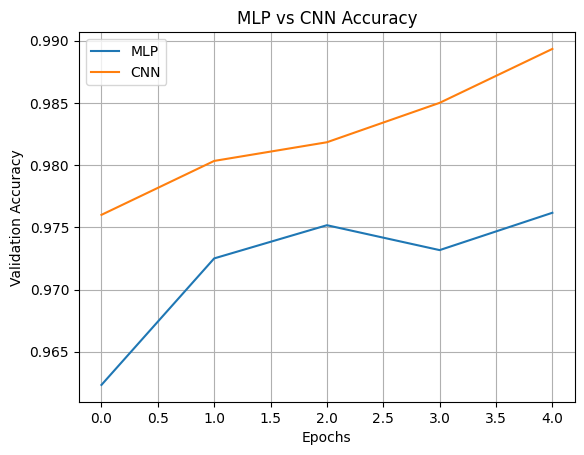

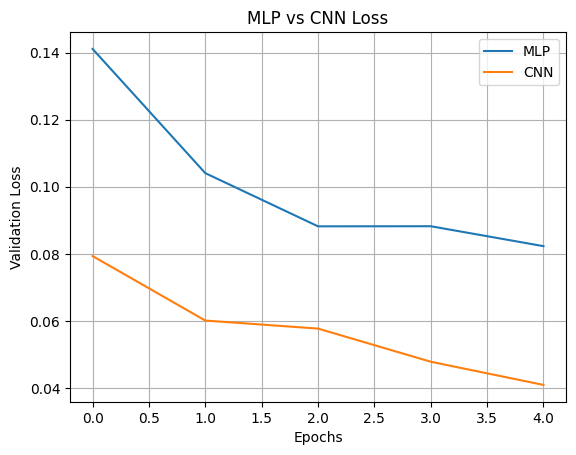

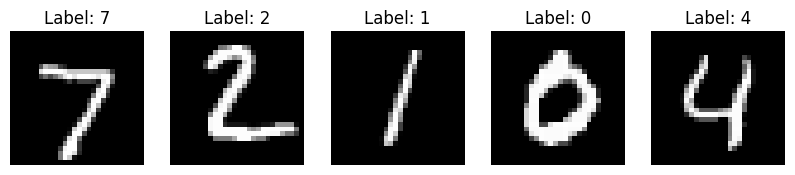


PROGRAM COMPLETED


In [8]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.layers import RandomRotation, RandomTranslation

# 1. Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize data
X_train = X_train / 255.0
X_test = X_test / 255.0

# Add channel dimension for CNN
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)


# 2. Build MLP model
mlp_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

mlp_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# Train MLP
mlp_history = mlp_model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

# Evaluate MLP
mlp_loss, mlp_acc = mlp_model.evaluate(X_test, y_test)


# 3. Data Augmentation
augmentation = Sequential([
    RandomRotation(0.05),
    RandomTranslation(0.1, 0.1)
])


# 4. Build CNN model
cnn_model = Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    augmentation,

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

cnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# Train CNN
cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

# Evaluate CNN
cnn_loss, cnn_acc = cnn_model.evaluate(X_test_cnn, y_test)


# 5. Compare Results
print("\nMODEL COMPARISON")

print("MLP Test Accuracy:", round(mlp_acc * 100, 2), "%")
print("CNN Test Accuracy:", round(cnn_acc * 100, 2), "%")

print("MLP Test Loss:", round(mlp_loss, 4))
print("CNN Test Loss:", round(cnn_loss, 4))


# 6. Plot Accuracy Comparison
plt.plot(mlp_history.history['val_accuracy'], label='MLP')
plt.plot(cnn_history.history['val_accuracy'], label='CNN')

plt.title("MLP vs CNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


# 7. Plot Loss Comparison
plt.plot(mlp_history.history['val_loss'], label='MLP')
plt.plot(cnn_history.history['val_loss'], label='CNN')

plt.title("MLP vs CNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid()
plt.show()


# 8. Display Sample Images
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i], cmap='gray')
    plt.title("Label: " + str(y_test[i]))
    plt.axis('off')

plt.show()

print("\nPROGRAM COMPLETED")